--- TABLA RESUMEN DE VINTAGE (ACUMULADO %) ---
cohort  2026-01 (Ene)  2026-02 (Feb)  2026-03 (Mar - Crisis)
mob                                                         
1                 1.9            1.5                     5.4
2                 5.4            5.1                    11.3
3                 7.1            7.3                    15.6
4                 8.2            8.4                    17.5
5                 9.6            9.9                    17.9
6                10.8           10.8                    17.9
7                10.8           10.8                    17.9
8                10.8           10.8                    17.9
9                10.8           10.8                    17.9
10               10.8           10.8                    17.9
11               10.8           10.8                    17.9
12               10.8           10.8                    17.9


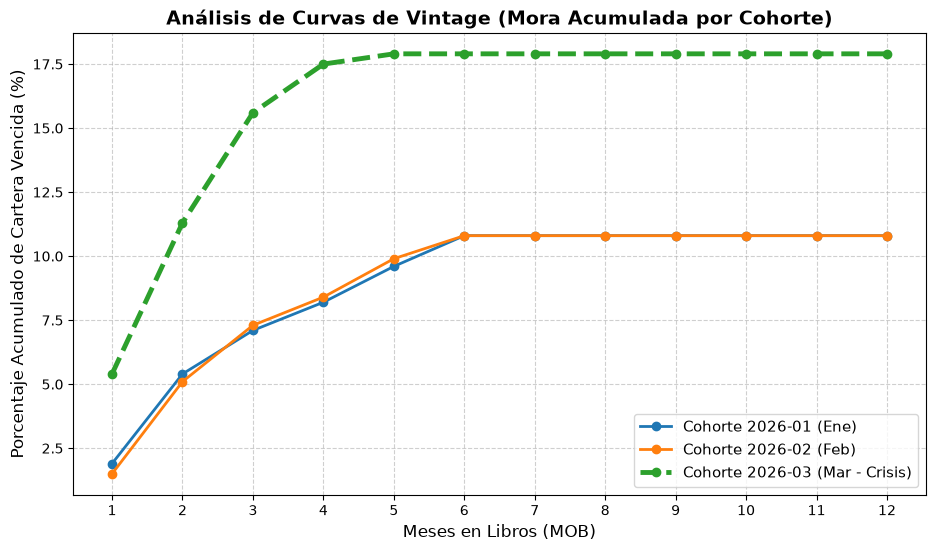

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Configuramos la simulación de nuestra cartera de créditos
np.random.seed(42)
n_prestamos_por_mes = 1000
cohortes = ['2026-01 (Ene)', '2026-02 (Feb)', '2026-03 (Mar - Crisis)']
max_mob = 12 # Meses en Libros (MOB) a evaluar

data = []

for cohort in cohortes:
    for loan_id in range(n_prestamos_por_mes):
        
        # Simulamos el riesgo base de la cohorte:
        # Haremos que la cohorte de Marzo tenga un factor de riesgo mayor (simulando un mal otorgamiento / péndulo laxo)
        if 'Mar' in cohort:
            prob_base_default = 0.18 # 18% terminan cayendo en impago
            # Mes típico de caída más temprano y agresivo
            default_mob = np.random.choice([1, 2, 3, 4, 5, 6, 999], p=[0.05, 0.06, 0.04, 0.02, 0.01, 0.00, 0.82])
        else:
            prob_base_default = 0.10 # 10% histórico normal
            default_mob = np.random.choice([1, 2, 3, 4, 5, 6, 999], p=[0.02, 0.03, 0.02, 0.01, 0.01, 0.01, 0.90])

        # Generamos el comportamiento mes a mes (MOB: Meses en Libros del 1 al 12)
        for mob in range(1, max_mob + 1):
            # El default es acumulativo: si cayó en el mes X, en los meses siguientes se mantiene en mora
            is_defaulted = 1 if mob >= default_mob else 0
            
            data.append({
                'cohort': cohort,
                'loan_id': loan_id,
                'mob': mob,
                'default': is_defaulted
            })

df_vintage = pd.DataFrame(data)

# 2. Creamos la tabla pivote: Filas = Meses en Libros (MOB), Columnas = Cohortes, Valores = % Promedio de Default Acumulado
df_pivot = df_vintage.groupby(['mob', 'cohort'])['default'].mean().unstack(level=1) * 100

print("--- TABLA RESUMEN DE VINTAGE (ACUMULADO %) ---")
print(df_pivot.round(2))

# 3. Graficamos las Curvas de Vintage
plt.figure(figsize=(11, 6))
for col in df_pivot.columns:
    # Estilo de línea más marcado para la cohorte de marzo
    lw = 3.5 if 'Mar' in col else 2
    linestyle = '--' if 'Mar' in col else '-'
    plt.plot(df_pivot.index, df_pivot[col], marker='o', linewidth=lw, linestyle=linestyle, label=f'Cohorte {col}')

plt.title("Análisis de Curvas de Vintage (Mora Acumulada por Cohorte)", fontsize=14, fontweight='bold')
plt.xlabel("Meses en Libros (MOB)", fontsize=12)
plt.ylabel("Porcentaje Acumulado de Cartera Vencida (%)", fontsize=12)
plt.xticks(range(1, max_mob + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

--- RESULTADOS DE LA SIMULACIÓN DE COBRANZA ---
Presupuesto restringido: Suficiente para llamar solo al 40% de la cartera (800 clientes).
Dinero recuperado con Estrategia 'Peor de los Peores' (Intuición pura): $479,535.23 MXN
Dinero recuperado con Estrategia 'Behavior Scoring' (Analítica Senior): $2,644,309.00 MXN
Diferencia a favor de la analítica: +$2,164,773.77 MXN extra recuperados.


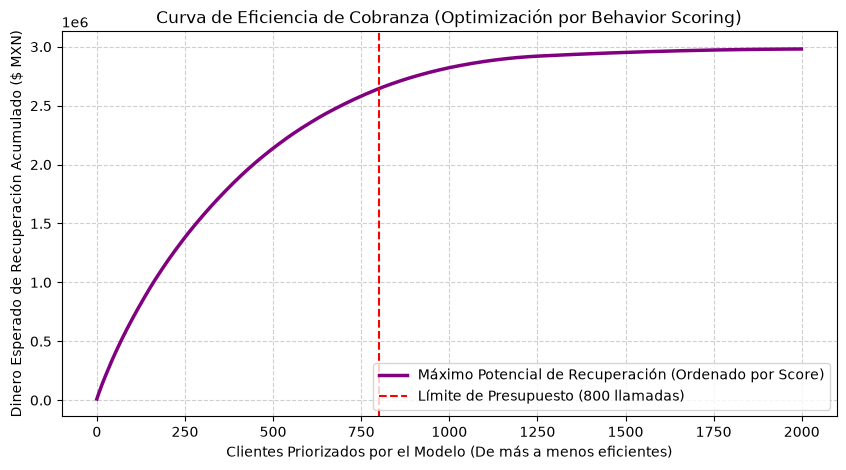

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulamos una cartera de 2,000 clientes en mora temprana (1 a 60 días)
np.random.seed(42)
n = 2000

df_cobranza = pd.DataFrame({
    'client_id': range(1, n + 1),
    'dias_mora': np.random.randint(1, 60, size=n),
    'monto_deuda': np.random.uniform(1000, 15000, size=n),
    'historial_cumplimiento_previo': np.random.uniform(0.1, 1.0, size=n) # 1.0 = cliente súper cumplido históricamente
})

# 2. Simulamos la Probabilidad real de que el cliente Pague si le Llamamos (Behavior Score)
# Lógica: Entre menos días de mora tenga Y mejor historial previo tenga, más probable es que pague.
df_cobranza['prob_pago'] = (
    0.8 * df_cobranza['historial_cumplimiento_previo'] - 
    0.01 * df_cobranza['dias_mora'] + 
    np.random.normal(0, 0.05, size=n)
).clip(0.01, 0.95)

# 3. Calculamos el RETORNO ESPERADO (Monto a recuperar x Probabilidad de pago)
df_cobranza['dinero_esperado_recuperar'] = df_cobranza['monto_deuda'] * df_cobranza['prob_pago']

# Costo fijo de una llamada de Call Center por cliente
costo_llamada = 150 # $150 MXN por llamada/gestión

df_cobranza['retorno_inversion_llamada'] = df_cobranza['dinero_esperado_recuperar'] / costo_llamada

# Ordenamos la cartera de MAYOR eficiencia a MENOR eficiencia (Behavior Scoring / Triage)
df_cobranza = df_cobranza.sort_values(by='retorno_inversion_llamada', ascending=False).reset_index(drop=True)

# 4. Simulamos el recorte presupuestal (Supongamos que solo tenemos presupuesto para llamar al 40% de los clientes)
porcentaje_presupuesto = 0.40
limite_llamadas = int(n * porcentaje_presupuesto)

# Estrategia 1: Asignar llamadas usando nuestro Behavior Scoring (De mayor a menor eficiencia)
df_cobranza['llamar_smart'] = 0
df_cobranza.loc[:limite_llamadas, 'llamar_smart'] = 1

# Estrategia 2: La mentalidad equivocada (Ir tras los "peores de los peores" / mayor días de mora y mayor deuda)
df_cobranza['dias_mora_descendente'] = df_cobranza['dias_mora'].rank(ascending=False)
df_cobranza['llamar_peores'] = 0
df_cobranza.loc[df_cobranza['dias_mora_descendente'] <= limite_llamadas, 'llamar_peores'] = 1

# 5. Calculamos el dinero real recuperado bajo cada estrategia
recuperado_smart = (df_cobranza['llamar_smart'] * df_cobranza['dinero_esperado_recuperar']).sum()
recuperado_peores = (df_cobranza['llamar_peores'] * df_cobranza['dinero_esperado_recuperar']).sum()

print("--- RESULTADOS DE LA SIMULACIÓN DE COBRANZA ---")
print(f"Presupuesto restringido: Suficiente para llamar solo al {int(porcentaje_presupuesto*100)}% de la cartera ({limite_llamadas} clientes).")
print(f"Dinero recuperado con Estrategia 'Peor de los Peores' (Intuición pura): ${recuperado_peores:,.2f} MXN")
print(f"Dinero recuperado con Estrategia 'Behavior Scoring' (Analítica Senior): ${recuperado_smart:,.2f} MXN")
print(f"Diferencia a favor de la analítica: +${(recuperado_smart - recuperado_peores):,.2f} MXN extra recuperados.")

# 6. Gráfica de Curva de Recuperación Acumulada
plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(df_cobranza['dinero_esperado_recuperar']), color='purple', linewidth=2.5, label='Máximo Potencial de Recuperación (Ordenado por Score)')
plt.axvline(limite_llamadas, color='red', linestyle='--', label=f'Límite de Presupuesto ({limite_llamadas} llamadas)')
plt.title("Curva de Eficiencia de Cobranza (Optimización por Behavior Scoring)")
plt.xlabel("Clientes Priorizados por el Modelo (De más a menos eficientes)")
plt.ylabel("Dinero Esperado de Recuperación Acumulado ($ MXN)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

--- COEFICIENTES DEL MODELO ECONOMÉTRICO (STRESS TEST) ---
Sensibilidad a la Inflación (Beta 1): 0.4405
Sensibilidad al Desempleo (Beta 2): 1.0608

--- RESULTADOS FINANCIEROS DE LA PRUEBA DE ESTRÉS ---

[Escenario Base (Normalidad)]
  Trimestre +1: Morosidad = 7.17% | Pérdida estimada = $71,729,549.73 MXN
  Trimestre +2: Morosidad = 7.32% | Pérdida estimada = $73,230,815.37 MXN
  Trimestre +3: Morosidad = 7.13% | Pérdida estimada = $71,289,048.25 MXN
  Trimestre +4: Morosidad = 7.28% | Pérdida estimada = $72,790,313.89 MXN

[Stress Test (Inflación x2 y Desempleo Disparado)]
  Trimestre +1: Morosidad = 11.81% | Pérdida estimada = $118,071,220.48 MXN
  Trimestre +2: Morosidad = 13.21% | Pérdida estimada = $132,104,091.86 MXN
  Trimestre +3: Morosidad = 12.69% | Pérdida estimada = $126,899,053.15 MXN
  Trimestre +4: Morosidad = 12.13% | Pérdida estimada = $121,253,512.95 MXN


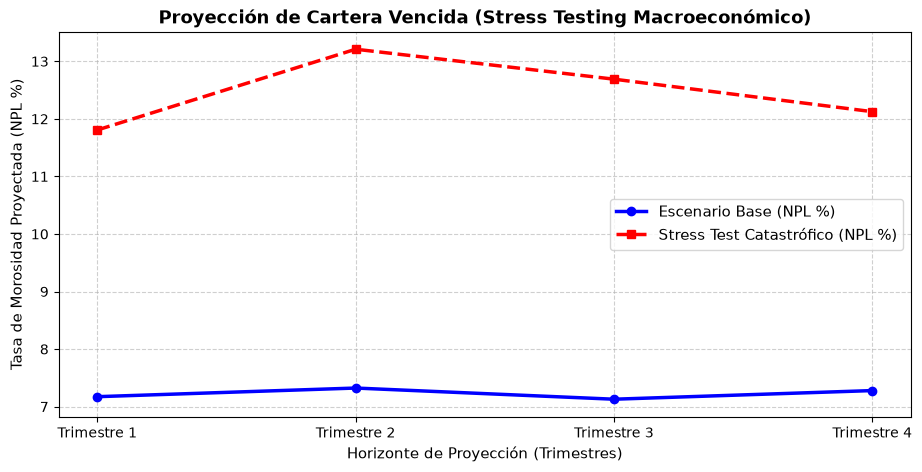

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. SIMULACIÓN DE DATOS HISTÓRICOS MACROECONÓMICOS (Últimos 24 Trimestres)
np.random.seed(42)
n_trimestres = 24

tiempo = np.arange(1, n_trimestres + 1)
# Inflación histórica trimestral simulada (%)
inflacion_hist = 4.0 + 1.5 * np.sin(tiempo / 3) + np.random.normal(0, 0.5, n_trimestres)
# Tasa de desempleo histórica simulada (%)
desempleo_hist = 3.8 + 0.2 * (tiempo / 4) + np.random.normal(0, 0.3, n_trimestres)

# Tasa de morosidad (NPL / Cartera Vencida %) influenciada por la inflación y el desempleo
npl_hist = 1.5 + 0.42 * inflacion_hist + 0.95 * desempleo_hist + np.random.normal(0, 0.15, n_trimestres)

df_macro = pd.DataFrame({
    'trimestre': [f'T{i%4+1} 20{20+i//4}' for i in range(n_trimestres)],
    'inflacion': inflacion_hist,
    'desempleo': desempleo_hist,
    'npl': npl_hist
})

# 2. ENTRENAMIENTO DEL MODELO ECONOMÉTRICO (Sensibilidad de la Cartera)
X = df_macro[['inflacion', 'desempleo']]
y = df_macro['npl']

modelo_stress = LinearRegression()
modelo_stress.fit(X, y)

print("--- COEFICIENTES DEL MODELO ECONOMÉTRICO (STRESS TEST) ---")
print(f"Sensibilidad a la Inflación (Beta 1): {modelo_stress.coef_[0]:.4f}")
print(f"Sensibilidad al Desempleo (Beta 2): {modelo_stress.coef_[1]:.4f}\n")

# 3. DEFINICIÓN DE ESCENARIOS FUTUROS (Próximos 4 trimestres / 1 año)
escenarios = {
    'Escenario Base (Normalidad)': {
        'inflacion': [4.5, 4.6, 4.4, 4.5],
        'desempleo': [4.0, 4.1, 4.0, 4.1]
    },
    'Stress Test (Inflación x2 y Desempleo Disparado)': {
        'inflacion': [9.0, 10.5, 9.8, 9.0], # Choque inflacionario severo
        'desempleo': [6.5, 7.2, 7.0, 6.8]  # Incremento drástico del desempleo
    }
}

# 4. PROYECCIÓN FINANCIERA Y PÉRDIDAS EN CARTERA
tamano_cartera_total = 1000000000 # Cartera total de $1,000 Millones de MXN
resultados = {}

for nombre, vars_macro in escenarios.items():
    df_esc = pd.DataFrame(vars_macro)
    npl_proyectado = modelo_stress.predict(df_esc[['inflacion', 'desempleo']])
    resultados[nombre] = npl_proyectado

print("--- RESULTADOS FINANCIEROS DE LA PRUEBA DE ESTRÉS ---")
for nombre, npls in resultados.items():
    print(f"\n[{nombre}]")
    for i, npl in enumerate(npls):
         perdida_mxn = tamano_cartera_total * (npl / 100)
         print(f"  Trimestre +{i+1}: Morosidad = {npl:.2f}% | Pérdida estimada = ${perdida_mxn:,.2f} MXN")

# 5. VISUALIZACIÓN GRÁFICA DE LA PRUEBA DE ESTRÉS
plt.figure(figsize=(11, 5))
plt.plot(range(1, 5), resultados['Escenario Base (Normalidad)'], marker='o', color='blue', linewidth=2.5, label='Escenario Base (NPL %)')
plt.plot(range(1, 5), resultados['Stress Test (Inflación x2 y Desempleo Disparado)'], marker='s', color='red', linestyle='--', linewidth=2.5, label='Stress Test Catastrófico (NPL %)')

plt.title("Proyección de Cartera Vencida (Stress Testing Macroeconómico)", fontsize=13, fontweight='bold')
plt.xlabel("Horizonte de Proyección (Trimestres)", fontsize=11)
plt.ylabel("Tasa de Morosidad Proyectada (NPL %)", fontsize=11)
plt.xticks([1, 2, 3, 4], ['Trimestre 1', 'Trimestre 2', 'Trimestre 3', 'Trimestre 4'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

In [4]:
import pandas as pd
import numpy as np

# 1. Simulamos una base de datos de créditos con 5,000 clientes
np.random.seed(42)
n = 5000

df_scorecard = pd.DataFrame({
    'edad': np.random.randint(18, 70, size=n),
    'default': np.random.choice([0, 1], size=n, p=[0.85, 0.15]) # 15% de morosidad global
})

# 2. Creamos rangos (bins) para la variable continua 'edad'
df_scorecard['rango_edad'] = pd.cut(df_scorecard['edad'], bins=[18, 25, 35, 50, 70], labels=['18-25', '26-35', '36-50', '51-70'])

# 3. Función para calcular WOE e Information Value (IV) de una variable categórica/agrupada
def calcular_woe_iv(df, variable_objetivo, variable_grupo):
    # Tabla pivote con conteo de Buenos (0) y Malos (1)
    tabla = pd.crosstab(df[variable_grupo], df[variable_objetivo], margins=False)
    tabla.columns = ['Buenos', 'Malos']
    
    # Totales generales
    total_buenos = tabla['Buenos'].sum()
    total_malos = tabla['Malos'].sum()
    
    # Porcentajes
%   tabla['Dist_Buenos'] = tabla['Buenos'] / total_buenos
    tabla['Dist_Malos'] = tabla['Malos'] / total_malos
    
    # Cálculo de WOE por categoría
    tabla['WOE'] = np.log(tabla['Dist_Buenos'] / tabla['Dist_Malos'])
    
    # Cálculo de IV parcial por categoría y sumatoria total
    tabla['IV_parcial'] = (tabla['Dist_Buenos'] - tabla['Dist_Malos']) * tabla['WOE']
    iv_total = tabla['IV_parcial'].sum()
    
    return tabla[['Buenos', 'Malos', 'WOE']], iv_total

# Ejecutamos la función para nuestra variable 'rango_edad'
tabla_woe, iv_edad = calcular_woe_iv(df_scorecard, 'default', 'rango_edad')

print("--- TABLA DE WEIGHT OF EVIDENCE (WOE) PARA EDAD ---")
print(tabla_woe.round(4))
print(f"\nInformation Value (IV) Total de la variable Edad: {iv_edad:.4f}")

IndentationError: unexpected indent (699482128.py, line 28)

In [5]:
import pandas as pd
import numpy as np

# 1. Simulamos una base de datos de créditos con 5,000 clientes
np.random.seed(42)
n = 5000

df_scorecard = pd.DataFrame({
    'edad': np.random.randint(18, 70, size=n),
    'default': np.random.choice([0, 1], size=n, p=[0.85, 0.15]) # 15% de morosidad global
})

# 2. Creamos rangos (bins) para la variable continua 'edad'
df_scorecard['rango_edad'] = pd.cut(df_scorecard['edad'], bins=[18, 25, 35, 50, 70], labels=['18-25', '26-35', '36-50', '51-70'])

# 3. Función para calcular WOE e Information Value (IV) de una variable categórica/agrupada
def calcular_woe_iv(df, variable_objetivo, variable_grupo):
    # Tabla pivote con conteo de Buenos (0) y Malos (1)
    tabla = pd.crosstab(df[variable_grupo], df[variable_objetivo], margins=False)
    tabla.columns = ['Buenos', 'Malos']
    
    # Totales generales
    total_buenos = tabla['Buenos'].sum()
    total_malos = tabla['Malos'].sum()
    
    # Porcentajes
    tabla['Dist_Buenos'] = tabla['Buenos'] / total_buenos
    tabla['Dist_Malos'] = tabla['Malos'] / total_malos
    
    # Cálculo de WOE por categoría
    tabla['WOE'] = np.log(tabla['Dist_Buenos'] / tabla['Dist_Malos'])
    
    # Cálculo de IV parcial por categoría y sumatoria total
    tabla['IV_parcial'] = (tabla['Dist_Buenos'] - tabla['Dist_Malos']) * tabla['WOE']
    iv_total = tabla['IV_parcial'].sum()
    
    return tabla[['Buenos', 'Malos', 'WOE']], iv_total

# Ejecutamos la función para nuestra variable 'rango_edad'
tabla_woe, iv_edad = calcular_woe_iv(df_scorecard, 'default', 'rango_edad')

print("--- TABLA DE WEIGHT OF EVIDENCE (WOE) PARA EDAD ---")
print(tabla_woe.round(4))
print(f"\nInformation Value (IV) Total de la variable Edad: {iv_edad:.4f}")

--- TABLA DE WEIGHT OF EVIDENCE (WOE) PARA EDAD ---
            Buenos  Malos     WOE
rango_edad                       
18-25          583     88  0.1008
26-35          774    145 -0.1153
36-50         1259    220 -0.0457
51-70         1589    249  0.0633

Information Value (IV) Total de la variable Edad: 0.0060


In [6]:
import pandas as pd
import numpy as np

# 1. Simulamos una base de datos de créditos con 5,000 clientes
np.random.seed(42)
n = 5000

edad = np.random.randint(18, 70, size=n)
df_scorecard = pd.DataFrame({'edad': edad})

# 2. Creamos una probabilidad de default condicionada a la edad (Relación real)
# Haremos que los jóvenes (18-25) y mayores (51-70) tengan mayor propensión al impago
def calcular_prob_default(row):
    e = row['edad']
    if e <= 25:
        return 0.28  # 28% de riesgo alto (menor experiencia crediticia)
    elif e <= 35:
        return 0.12  # 12% de riesgo moderado
    elif e <= 50:
        return 0.08  # 8% de riesgo bajo (etapa económicamente más estable)
    else:
        return 0.22  # 22% de riesgo medio-alto

df_scorecard['prob_default'] = df_scorecard.apply(calcular_prob_default, axis=1)
df_scorecard['default'] = np.random.binomial(1, df_scorecard['prob_default'])

# 3. Creamos rangos (bins) para la variable continua 'edad'
df_scorecard['rango_edad'] = pd.cut(df_scorecard['edad'], bins=[18, 25, 35, 50, 70], labels=['18-25', '26-35', '36-50', '51-70'])

# 4. Función para calcular WOE e Information Value (IV)
def calcular_woe_iv(df, variable_objetivo, variable_grupo):
    tabla = pd.crosstab(df[variable_grupo], df[variable_objetivo], margins=False)
    tabla.columns = ['Buenos', 'Malos']
    
    total_buenos = tabla['Buenos'].sum()
    total_malos = tabla['Malos'].sum()
    
    tabla['Dist_Buenos'] = tabla['Buenos'] / total_buenos
    tabla['Dist_Malos'] = tabla['Malos'] / total_malos
    
    tabla['WOE'] = np.log(tabla['Dist_Buenos'] / tabla['Dist_Malos'])
    tabla['IV_parcial'] = (tabla['Dist_Buenos'] - tabla['Dist_Malos']) * tabla['WOE']
    iv_total = tabla['IV_parcial'].sum()
    
    return tabla[['Buenos', 'Malos', 'WOE']], iv_total

# Ejecutamos la función para nuestra variable 'rango_edad'
tabla_woe, iv_edad = calcular_woe_iv(df_scorecard, 'default', 'rango_edad')

print("--- TABLA DE WEIGHT OF EVIDENCE (WOE) PARA EDAD ---")
print(tabla_woe.round(4))
print(f"\nInformation Value (IV) Total de la variable Edad: {iv_edad:.4f}")

--- TABLA DE WEIGHT OF EVIDENCE (WOE) PARA EDAD ---
            Buenos  Malos     WOE
rango_edad                       
18-25          494    177 -0.6381
26-35          804    115  0.2802
36-50         1356    123  0.7356
51-70         1472    366 -0.2727

Information Value (IV) Total de la variable Edad: 0.2380


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 1. Creamos un diccionario con los valores de WOE que calculamos para la edad
woe_mapping = tabla_woe['WOE'].to_dict()

# 2. Mapeamos esos valores de WOE de regreso a nuestro DataFrame principal de clientes
df_scorecard['edad_woe'] = df_scorecard['rango_edad'].map(woe_mapping)

# 3. Preparamos las matrices X (Variable predictora transformada en WOE) y y (Variable objetivo: Default)
X = df_scorecard[['edad_woe']]
y = df_scorecard['default']

# 4. Entrenamos la Regresión Logística
modelo_logistico = LogisticRegression()
modelo_logistico.fit(X, y)

print("--- PARÁMETROS DE LA REGRESIÓN LOGÍSTICA ---")
print(f"Intercepto (Beta 0): {modelo_logistico.intercept_[0]:.4f}")
print(f"Coeficiente de la Edad en WOE (Beta 1): {modelo_logistico.coef_[0][0]:.4f}\n")

# 5. Generamos las probabilidades predichas de impago para cada cliente
df_scorecard['prob_default_modelo'] = modelo_logistico.predict_proba(X)[:, 1]

# 6. Evaluamos el rendimiento del modelo con el ROC-AUC
auc = roc_auc_score(y, df_scorecard['prob_default_modelo'])
print(f"Poder Discriminatorio del Modelo (ROC-AUC): {auc:.4f}")

# 7. Tabla resumen para ver cómo el modelo traduce el WOE en probabilidad real de impago
resumen_final = df_scorecard.groupby('rango_edad', observed=False).agg(
    woe=('edad_woe', 'first'),
    tasa_default_real=('default', 'mean'),
    prob_predicha_modelo=('prob_default_modelo', 'mean')
)
print("\n--- RESUMEN FINAL: WOE VS PROBABILIDAD DE IMPAGO ---")
print(resumen_final.round(4))

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 1. Creamos un diccionario con los valores de WOE que calculamos para la edad
woe_mapping = tabla_woe['WOE'].to_dict()

# 2. Mapeamos los valores de WOE de regreso al DataFrame
df_scorecard['edad_woe'] = df_scorecard['rango_edad'].map(woe_mapping)

# 3. ¡IMPORTANTE! Limpiamos cualquier valor nulo (NaN) que haya quedado en el mapeo
df_scorecard = df_scorecard.dropna(subset=['edad_woe', 'default'])

# 4. Preparamos las matrices X y y
X = df_scorecard[['edad_woe']]
y = df_scorecard['default']

# 5. Entrenamos la Regresión Logística
modelo_logistico = LogisticRegression()
modelo_logistico.fit(X, y)

print("--- PARÁMETROS DE LA REGRESIÓN LOGÍSTICA ---")
print(f"Intercepto (Beta 0): {modelo_logistico.intercept_[0]:.4f}")
print(f"Coeficiente de la Edad en WOE (Beta 1): {modelo_logistico.coef_[0][0]:.4f}\n")

# 6. Generamos las probabilidades predichas de impago
df_scorecard['prob_default_modelo'] = modelo_logistico.predict_proba(X)[:, 1]

# 7. Evaluamos el rendimiento con el ROC-AUC
auc = roc_auc_score(y, df_scorecard['prob_default_modelo'])
print(f"Poder Discriminatorio del Modelo (ROC-AUC): {auc:.4f}")

# 8. Tabla resumen final
resumen_final = df_scorecard.groupby('rango_edad', observed=False).agg(
    woe=('edad_woe', 'first'),
    tasa_default_real=('default', 'mean'),
    prob_predicha_modelo=('prob_default_modelo', 'mean')
)
print("\n--- RESUMEN FINAL: WOE VS PROBABILIDAD DE IMPAGO ---")
print(resumen_final.round(4))

--- PARÁMETROS DE LA REGRESIÓN LOGÍSTICA ---
Intercepto (Beta 0): -1.6637
Coeficiente de la Edad en WOE (Beta 1): -0.9937

Poder Discriminatorio del Modelo (ROC-AUC): 0.6306

--- RESUMEN FINAL: WOE VS PROBABILIDAD DE IMPAGO ---
                 woe  tasa_default_real  prob_predicha_modelo
rango_edad                                                   
18-25      -0.638103             0.2638                0.2632
26-35       0.280179             0.1251                0.1254
36-50       0.735622             0.0832                0.0836
51-70      -0.272745             0.1991                0.1990
